<a href="https://colab.research.google.com/github/kabirnagdev/bloomberg-terminal/blob/main/Knowledge_graph_finance_RAG_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Graph RAG on a Financial CSV (Knowledge Graph + Groq free tier) - Kaggle-ready

Dataset: Kaggle **nitindatta/finance-data** (`Finance_data.csv`). Works with any CSV.

**Updated for Oct 2026:** Groq shut down `llama-3.3-70b-versatile`, `llama-3.1-8b-instant` (and the older `llama-3.3-70b-specdec` / `llama3-*` IDs) on the free plan, so this notebook uses **`openai/gpt-oss-120b`** (free, 30 req/min, 8K tokens/min, 200K tokens/day) with automatic fallback to `openai/gpt-oss-20b` and `qwen/qwen3.8-27b`.

### Kaggle setup (do this once)
1. Notebook sidebar -> **Add Input** -> search `nitindatta/finance-data` (or leave it: the notebook falls back to `kagglehub`).
2. **Settings -> Internet -> On** (needed for Groq and for downloading the embedding model).
3. **Add-ons -> Secrets** -> add a secret named `GROQ_API_KEY` (get a free key at console.groq.com/keys) and tick it for this notebook.

Pipeline (Medium article CSV -> RDF -> graph, and Buehler 2024: ontological KG, keyword extraction, 2-hop expansion, multi-step prompting):

1. **CSV -> Knowledge Graph** (record nodes, entity nodes, `associated_with` edges with count + lift)
2. **RDF export** (Turtle)
3. **Vector index** (all-MiniLM-L6-v2)
4. **Graph RAG:** keywords -> entity linking -> 2-hop expansion -> triples + records + exact stats -> LLM answer
5. Multi-step answer, plain-RAG baseline, visualisation

## 1. Install

In [1]:
%pip install -q -U groq rdflib sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 760.7/760.7 kB 21.7 MB/s eta 0:00:00


## 2. Configuration
The API key is read from Kaggle Secrets (`GROQ_API_KEY`), then the environment, then a prompt. Never paste it into code.

In [2]:
import os, getpass, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

if not os.getenv("GROQ_API_KEY"):
    try:                                              # Kaggle Secrets
        from kaggle_secrets import UserSecretsClient
        os.environ["GROQ_API_KEY"] = UserSecretsClient().get_secret("GROQ_API_KEY")
    except Exception:
        os.environ["GROQ_API_KEY"] = getpass.getpass("Groq API key: ")

# Free-tier chat models on Groq as of Oct 2026, in order of preference.
GROQ_MODELS    = ["openai/gpt-oss-120b", "openai/gpt-oss-20b", "qwen/qwen3.8-27b"]
EMBED_MODEL    = "all-MiniLM-L6-v2"
KAGGLE_DATASET = "nitindatta/finance-data"
KAGGLE_FILE    = "Finance_data.csv"
LOCAL_CSV      = None          # e.g. "my_data.csv" to skip Kaggle

# graph-building knobs
MAX_ENTITY_VALUES = 25     # a column with <= this many distinct values becomes entity nodes
MIN_LIFT          = 1.5    # keep associations at least this much stronger than chance
MAX_ASSOC_EDGES   = 400

# Groq free tier allows 8,000 tokens/minute per model -> keep prompts small and paced
TPM_BUDGET        = 6500
MAX_CONTEXT_CHARS = 7000
RUN_CHAT          = False  # set True to use the interactive chat cell at the end

Groq API key: ··········


## 3. Load the CSV
Order: `LOCAL_CSV` -> dataset attached to the Kaggle notebook (`/kaggle/input`) -> `kagglehub` download.

In [3]:
import glob
import pandas as pd

def find_csv():
    if LOCAL_CSV:
        return LOCAL_CSV
    hits = glob.glob(f"/kaggle/input/**/{KAGGLE_FILE}", recursive=True)
    if hits:
        return hits[0]
    hits = [p for p in glob.glob("/kaggle/input/**/*.csv", recursive=True) if "financ" in p.lower()]
    return hits[0] if hits else None

path = find_csv()
if path:
    print("Reading", path)
    df = pd.read_csv(path)
else:
    import kagglehub
    d = kagglehub.dataset_download(KAGGLE_DATASET)
    print("Downloaded to", d)
    df = pd.read_csv(os.path.join(d, KAGGLE_FILE))

df.columns = [str(c).strip() for c in df.columns]
df = df.dropna(how="all").reset_index(drop=True)
print(df.shape)
df.head()

100%|██████████| 2.89k/2.89k [00:00<00:00, 4.73MB/s]

Extracting files...
Downloaded to /root/.cache/kagglehub/datasets/nitindatta/finance-data/versions/1
(40, 24)


,gender,age,Investment_Avenues,Mutual_Funds,Equity_Market,Debentures,Government_Bonds,Fixed_Deposits,PPF,Gold,...,Duration,Invest_Monitor,Expect,Avenue,What are your savings objectives?,Reason_Equity,Reason_Mutual,Reason_Bonds,Reason_FD,Source
0,Female,34,Yes,1,2,5,3,7,6,4,...,1-3 years,Monthly,20%-30%,Mutual Fund,Retirement Plan,Capital Appreciation,Better Returns,Safe Investment,Fixed Returns,Newspapers and Magazines
1,Female,23,Yes,4,3,2,1,5,6,7,...,More than 5 years,Weekly,20%-30%,Mutual Fund,Health Care,Dividend,Better Returns,Safe Investment,High Interest Rates,Financial Consultants
2,Male,30,Yes,3,6,4,2,5,1,7,...,3-5 years,Daily,20%-30%,Equity,Retirement Plan,Capital Appreciation,Tax Benefits,Assured Returns,Fixed Returns,Television
3,Male,22,Yes,2,1,3,7,6,4,5,...,Less than 1 year,Daily,10%-20%,Equity,Retirement Plan,Dividend,Fund Diversification,Tax Incentives,High Interest Rates,Internet
4,Female,24,No,2,1,3,6,4,5,7,...,Less than 1 year,Daily,20%-30%,Equity,Retirement Plan,Capital Appreciation,Better Returns,Safe Investment,Risk Free,Internet


## 4. CSV -> Knowledge Graph
* `Record` node per row, edges `record -[column]-> entity`.
* Entity nodes for low-cardinality columns (this also covers 1-7 ranking columns).
* `associated_with` edges between entities of *different* columns when they co-occur more often than chance (**lift**) and at least a minimum number of times.

In [4]:
import re, itertools
import numpy as np
import networkx as nx
from collections import Counter

def slug(v):
    return re.sub(r"[^A-Za-z0-9_]+", "_", str(v).strip()).strip("_") or "unknown"

def is_entity_col(s):
    n = s.nunique(dropna=True)
    if pd.api.types.is_float_dtype(s):
        vals = s.dropna()
        if not (vals % 1 == 0).all():          # genuinely continuous -> property
            return False
    return 1 < n <= MAX_ENTITY_VALUES and n <= 0.6 * len(s)

def py(v):
    return v.item() if hasattr(v, "item") else v

def row_to_text(i, row):
    return f"Record {i} - " + "; ".join(f"{c}: {v}" for c, v in row.items() if pd.notna(v))

def build_kg(df):
    G, N = nx.DiGraph(), len(df)
    ent_cols  = [c for c in df.columns if is_entity_col(df[c])]
    prop_cols = [c for c in df.columns if c not in ent_cols]
    rec_entities = {}

    for i, row in df.iterrows():
        rid = f"record:{i}"
        G.add_node(rid, ntype="Record", row=i, label=f"Record {i}", text=row_to_text(i, row),
                   props={c: py(row[c]) for c in prop_cols if pd.notna(row[c])})
        ents = set()
        for c in ent_cols:
            v = row[c]
            if pd.isna(v):
                continue
            eid = f"{c}={v}"
            if eid not in G:
                G.add_node(eid, ntype="Entity", col=c, value=str(v), label=f"{c}: {v}")
            G.add_edge(rid, eid, predicate=c)
            ents.add(eid)
        rec_entities[rid] = ents

    node_cnt, pair_cnt = Counter(), Counter()
    for ents in rec_entities.values():
        node_cnt.update(ents)
        for a, b in itertools.combinations(sorted(ents), 2):
            if G.nodes[a]["col"] != G.nodes[b]["col"]:
                pair_cnt[(a, b)] += 1

    min_co = max(3, int(0.05 * N))
    cands = []
    for (a, b), co in pair_cnt.items():
        lift = co * N / (node_cnt[a] * node_cnt[b])
        if co >= min_co and lift >= MIN_LIFT:
            cands.append((lift * np.log1p(co), a, b, co, lift))
    cands.sort(reverse=True)

    A = nx.Graph()            # entity-only association layer used for hop expansion
    for _, a, b, co, lift in cands[:MAX_ASSOC_EDGES]:
        G.add_edge(a, b, predicate="associated_with", count=co, lift=round(lift, 2))
        A.add_edge(a, b, count=co, lift=lift)
    return G, A, ent_cols, prop_cols

G, A, ent_cols, prop_cols = build_kg(df)
n_rec = sum(1 for _, d in G.nodes(data=True) if d["ntype"] == "Record")
n_ent = sum(1 for _, d in G.nodes(data=True) if d["ntype"] == "Entity")
print(f"Records: {n_rec} | Entities: {n_ent} | Edges: {G.number_of_edges()} | Association edges: {A.number_of_edges()}")
print("Entity columns  :", ent_cols)
print("Property columns:", prop_cols)

Records: 40 | Entities: 107 | Edges: 1144 | Association edges: 184
Entity columns  : ['gender', 'age', 'Investment_Avenues', 'Mutual_Funds', 'Equity_Market', 'Debentures', 'Government_Bonds', 'Fixed_Deposits', 'PPF', 'Gold', 'Stock_Marktet', 'Factor', 'Objective', 'Purpose', 'Duration', 'Invest_Monitor', 'Expect', 'Avenue', 'What are your savings objectives?', 'Reason_Equity', 'Reason_Mutual', 'Reason_Bonds', 'Reason_FD', 'Source']
Property columns: []


### Inspect the strongest relationships the graph discovered

In [5]:
rows = [(G.nodes[a]["label"], G.nodes[b]["label"], d["count"], round(d["lift"], 2)) for a, b, d in A.edges(data=True)]
assoc_df = pd.DataFrame(rows, columns=["entity_A", "entity_B", "co-occurrences", "lift"]).sort_values("lift", ascending=False)
assoc_df.head(15)

,entity_A,entity_B,co-occurrences,lift
0,Investment_Avenues: No,Source: Internet,3,10.00
11,Government_Bonds: 2,Reason_Mutual: Tax Benefits,3,10.00
17,Debentures: 3,Objective: Income,3,10.00
1,Investment_Avenues: No,Stock_Marktet: No,3,8.00
6,Source: Internet,Debentures: 3,3,7.50
5,Source: Internet,Invest_Monitor: Daily,3,7.50
7,Source: Internet,Stock_Marktet: No,3,6.00
29,Government_Bonds: 6,age: 24,3,5.71
48,Debentures: 6,age: 26,3,3.75
85,Fixed_Deposits: 1,age: 26,3,3.75


## 5. Export as RDF (rdflib, Turtle)
Every entity is typed by its column class, as in the article's RDF mapping. Saved to the working dir (`/kaggle/working` on Kaggle).

In [6]:
from rdflib import Graph as RDFGraph, Namespace, Literal, URIRef, RDF, RDFS, XSD

FIN = Namespace("http://example.org/finance/")

def kg_to_rdf(G):
    g = RDFGraph(); g.bind("fin", FIN)
    uri = {}
    for n, d in G.nodes(data=True):
        if d["ntype"] == "Record":
            u = URIRef(f"{FIN}record/{d['row']}"); uri[n] = u
            g.add((u, RDF.type, FIN.Record))
            g.add((u, FIN.text, Literal(d["text"])))
            for c, v in d["props"].items():
                dt = XSD.integer if isinstance(v, int) and not isinstance(v, bool) else XSD.double if isinstance(v, float) else None
                g.add((u, FIN[slug(c)], Literal(v, datatype=dt) if dt else Literal(str(v))))
        else:
            u = URIRef(f"{FIN}{slug(d['col'])}/{slug(d['value'])}"); uri[n] = u
            g.add((u, RDF.type, FIN[slug(d["col"]).capitalize()]))
            g.add((u, RDFS.label, Literal(d["label"])))
    for a, b, d in G.edges(data=True):
        g.add((uri[a], FIN[slug(d["predicate"])], uri[b]))
    return g

rdf_graph = kg_to_rdf(G)
rdf_graph.serialize("finance_kg.ttl", format="turtle")
print("RDF triples:", len(rdf_graph), "-> saved finance_kg.ttl")

RDF triples: 1438 -> saved finance_kg.ttl


## 6. Embeddings / vector index
Uses `all-MiniLM-L6-v2`. If the model cannot be downloaded (e.g. Kaggle Internet is off) it falls back to a local character n-gram embedder so the notebook still runs (retrieval quality is lower).

In [7]:
try:
    from sentence_transformers import SentenceTransformer
    _embedder = SentenceTransformer(EMBED_MODEL)
    def embed(texts):
        return _embedder.encode(list(texts), normalize_embeddings=True, show_progress_bar=False)
    EMBED_BACKEND = EMBED_MODEL
except Exception as e:
    print("WARNING: could not load", EMBED_MODEL, "->", type(e).__name__, "- using hashing fallback")
    from sklearn.feature_extraction.text import HashingVectorizer
    _hv = HashingVectorizer(analyzer="char_wb", ngram_range=(3, 5), n_features=4096, norm="l2", alternate_sign=False)
    def embed(texts):
        return _hv.transform(list(texts)).toarray()
    EMBED_BACKEND = "hashing-fallback"
print("Embedding backend:", EMBED_BACKEND)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding backend: all-MiniLM-L6-v2


In [8]:
rec_ids   = [n for n, d in G.nodes(data=True) if d["ntype"] == "Record"]
ent_ids   = [n for n, d in G.nodes(data=True) if d["ntype"] == "Entity"]
rec_index = {n: i for i, n in enumerate(rec_ids)}
all_cols  = list(df.columns)

rec_vecs = embed([G.nodes[n]["text"]  for n in rec_ids])
ent_vecs = embed([G.nodes[n]["label"] for n in ent_ids])
col_vecs = embed(all_cols)
print(rec_vecs.shape, ent_vecs.shape, col_vecs.shape)

(40, 384) (107, 384) (24, 384)


## 7. Groq LLM (free tier)
* Picks the first available model from `GROQ_MODELS` (checks `models.list()`), and falls back automatically if a model is decommissioned.
* The free tier allows **8,000 tokens/minute**, so calls are paced with a sliding-window budget and retried on HTTP 429 (honouring `retry-after`).
* `gpt-oss` models are reasoning models: `reasoning_effort="low"` keeps them fast and leaves room for the visible answer.

In [9]:
import time, collections
from groq import Groq, RateLimitError, BadRequestError, NotFoundError

_client = Groq(api_key=os.environ["GROQ_API_KEY"], max_retries=0)

def _pick_models():
    try:
        avail = {m.id for m in _client.models.list().data}
    except Exception as e:
        print("Could not list models (", type(e).__name__, ") - trying preferred order.")
        return list(GROQ_MODELS)
    ok = [m for m in GROQ_MODELS if m in avail]
    if not ok:
        chat = sorted(a for a in avail if "whisper" not in a and "orpheus" not in a and "guard" not in a)
        raise RuntimeError(f"None of {GROQ_MODELS} are available. Models on your account: {chat}")
    return ok

_models = _pick_models()
print("Using model order:", _models)

_usage = collections.deque()          # (timestamp, tokens) over the last 60 s

def _est(text):
    return int(len(text) / 3.2) + 1

def _wait_for_budget(need):
    while True:
        now = time.time()
        while _usage and now - _usage[0][0] > 60:
            _usage.popleft()
        used = sum(t for _, t in _usage)
        if not _usage or used + need <= TPM_BUDGET:
            return
        wait = 60 - (now - _usage[0][0]) + 0.5
        print(f"  [pacing for 8K TPM free limit: waiting {wait:.0f}s]")
        time.sleep(max(wait, 1))

def llm(prompt, system="You are a careful financial data analyst.", temperature=0.0, max_tokens=1500):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
    for model in list(_models):
        budget_tokens = max_tokens
        for attempt in range(6):
            _wait_for_budget(_est(system + prompt) + budget_tokens)
            kw = dict(model=model, messages=msgs, temperature=temperature, max_completion_tokens=budget_tokens)
            if model.startswith("openai/gpt-oss"):
                kw["reasoning_effort"] = "low"
            try:
                r = _client.chat.completions.create(**kw)
            except RateLimitError as e:
                hdr = getattr(getattr(e, "response", None), "headers", {}) or {}
                try:
                    wait = float(hdr.get("retry-after", 15))
                except Exception:
                    wait = 15.0
                print(f"  [429 from Groq, retrying in {wait:.0f}s]")
                time.sleep(min(wait + 1, 70)); continue
            except (BadRequestError, NotFoundError) as e:
                if any(s in str(e).lower() for s in ("decommission", "not found", "does not exist", "model_not_found", "no longer supported")):
                    print(f"  [model {model} unavailable -> dropping it, trying next]")
                    if model in _models: _models.remove(model)
                    break
                raise
            _usage.append((time.time(), getattr(r.usage, "total_tokens", None) or kw["max_completion_tokens"]))
            text = (r.choices[0].message.content or "").strip()
            if text:
                return text
            budget_tokens = min(budget_tokens * 2, 4000)       # reasoning ate the budget -> retry with more
    raise RuntimeError("All Groq models failed or returned empty output.")

print(llm("Reply with exactly the word: OK"))

Using model order: ['openai/gpt-oss-120b', 'openai/gpt-oss-20b', 'qwen/qwen3.8-27b']
OK


## 8. Graph RAG retrieval
1. **Keyword extraction** with the LLM.
2. **Entity linking:** keywords -> graph nodes (semantic + lexical). Also links relevant columns.
3. **2-hop expansion** over `associated_with` edges -> directed triples.
4. **Records:** records attached to the seed entities plus top vector hits.
5. **Exact statistics** straight from the data.

In [10]:
import json

def extract_keywords(question):
    cols = "; ".join(all_cols)
    out = llm(
        "Extract the key entities and concepts from the question for a knowledge-graph lookup.\n"
        f"Dataset columns: {cols}\n"
        "Return ONLY a JSON list of at most 6 short strings.\n"
        f"Question: {question}"
    )
    m = re.search(r"\[.*?\]", out, re.S)
    try:
        kws = [str(k) for k in json.loads(m.group(0))] if m else []
    except Exception:
        kws = []
    return kws or [w for w in re.findall(r"[A-Za-z_]{4,}", question)][:6]

def link(question, keywords, ent_thr=0.40, col_thr=0.45, max_seeds=6):
    queries = [question] + keywords
    qv = embed(queries)
    sims, score = qv @ ent_vecs.T, {}
    for row in sims:
        for j in np.argsort(-row)[:3]:
            if row[j] >= ent_thr:
                score[ent_ids[j]] = max(score.get(ent_ids[j], 0), float(row[j]))
    for kw in keywords:                      # lexical boost
        k = kw.lower().strip()
        for n in ent_ids:
            if k == str(G.nodes[n]["value"]).lower() or (len(k) > 3 and k in G.nodes[n]["label"].lower()):
                score[n] = 1.0
    seeds = [n for n, _ in sorted(score.items(), key=lambda x: -x[1])[:max_seeds]]
    csims, cscore = qv @ col_vecs.T, {}
    for row in csims:
        for j in np.argsort(-row)[:2]:
            if row[j] >= col_thr:
                cscore[all_cols[j]] = max(cscore.get(all_cols[j], 0), float(row[j]))
    for kw in keywords:
        for c in all_cols:
            if len(kw) > 3 and kw.lower() in c.lower():
                cscore[c] = 1.0
    cols = [c for c, _ in sorted(cscore.items(), key=lambda x: -x[1])[:3]]
    return seeds, cols

def expand(seeds, hops=2, per_hop=8):
    """Directed triples from the association layer, up to `hops` away from the seeds."""
    triples, seen = [], set()
    frontier, visited = set(seeds), set(seeds)
    for h in range(1, hops + 1):
        cands = []
        for n in frontier:
            if n not in A:
                continue
            for nb in A.neighbors(n):
                d = A[n][nb]
                cands.append((d["lift"] * np.log1p(d["count"]), n, nb, d))
        cands.sort(key=lambda x: -x[0])
        nxt = set()
        for _, n, nb, d in cands:
            key = frozenset((n, nb))
            if key in seen:
                continue
            seen.add(key)
            triples.append({"s": G.nodes[n]["label"], "p": "associated_with", "o": G.nodes[nb]["label"],
                            "hop": h, "count": d["count"], "lift": round(d["lift"], 2)})
            if nb not in visited:
                nxt.add(nb)
            if sum(1 for t in triples if t["hop"] == h) >= per_hop:
                break
        visited |= nxt
        frontier = nxt
    return triples

def profile(seeds, cols, top=5):
    lines, N = [], len(df)
    for c in cols:
        vc = df[c].value_counts(dropna=True).head(top)
        lines.append(f"Distribution of '{c}' (all {N} records): " + ", ".join(f"{k}={v}" for k, v in vc.items()))
    for s in seeds:
        d = G.nodes[s]
        idx = [G.nodes[u]["row"] for u, _ in G.in_edges(s) if G.nodes[u]["ntype"] == "Record"]
        sub = df.loc[idx]
        lines.append(f"{d['label']}: {len(sub)}/{N} records ({100*len(sub)/N:.0f}%).")
        for c in [c for c in cols if c != d["col"]][:2]:
            vc = sub[c].value_counts().head(top)
            lines.append(f"   among them, '{c}': " + ", ".join(f"{k}={v}" for k, v in vc.items()))
    return "\n".join(lines) or "(no entity or column matched)"

def retrieve(question, hops=2, k_vec=4, k_graph=4):
    kws = extract_keywords(question)
    seeds, cols = link(question, kws)
    triples = expand(seeds, hops)
    qv = embed([question])[0]
    sims = rec_vecs @ qv
    vec_hits = list(np.argsort(-sims)[:k_vec])
    adj = {rec_index[u] for s in seeds for u, _ in G.in_edges(s) if G.nodes[u]["ntype"] == "Record"}
    graph_hits = sorted(adj, key=lambda i: -sims[i])[:k_graph]
    rec_idx = list(dict.fromkeys(graph_hits + vec_hits))
    return {
        "keywords": kws,
        "seeds": seeds,
        "columns": cols,
        "triples": triples,
        "records": [G.nodes[rec_ids[i]]["text"] for i in rec_idx],
        "profile": profile(seeds, cols),
    }

## 9. Answer generation

In [11]:
OVERVIEW = f"Dataset with {len(df)} records and columns: " + "; ".join(all_cols)

def format_context(r):
    tri = "\n".join(f"- ('{t['s']}', '{t['p']}', '{t['o']}')  [hop {t['hop']}, n={t['count']}, lift={t['lift']}]"
                    for t in r["triples"]) or "(none)"
    rec = "\n".join(f"- {x}" for x in r["records"]) or "(none)"
    ctx = (f"EXTRACTED KEYWORDS: {r['keywords']}\n\n"
           f"EXACT STATISTICS:\n{r['profile']}\n\n"
           f"KNOWLEDGE GRAPH RELATIONSHIPS (directed triples, up to 2 hops):\n{tri}\n\n"
           f"RELEVANT RECORDS:\n{rec}")
    return ctx[:MAX_CONTEXT_CHARS]          # keep the request well under the 8K tokens/min free limit

def build_prompt(question, r, extra=""):
    return f"""Answer the question using ONLY the context below.
- EXACT STATISTICS are computed from the full dataset: use them for counts and percentages.
- KNOWLEDGE GRAPH RELATIONSHIPS show which values co-occur more than chance (lift > 1 = positive association); this is correlation in a small survey, not causation.
- RELEVANT RECORDS are individual examples.
If the context is insufficient, say so. Never invent numbers. This is data analysis, not financial advice.

{OVERVIEW}

{format_context(r)}
{extra}
Question: {question}
Answer:"""

def ask(question, hops=2, show_context=False):
    r = retrieve(question, hops)
    if show_context:
        print(format_context(r), "\n" + "-" * 60)
    return llm(build_prompt(question, r)), r

def ask_tot(question, hops=2):
    """Multi-step sampling inspired by Tree-of-Thought (paper, Fig. 5b)."""
    r = retrieve(question, hops)
    ctx = format_context(r)
    t1 = llm(f"Generate a short list of initial thoughts relevant for answering this question: '{question}'. "
             f"Use the context. Do not answer the question.\n\n{ctx}", temperature=0.7)
    t2 = llm(f"Read this: '{t1}'. List the most important concepts to answer the question '{question}'.")
    ans = llm(build_prompt(question, r, extra=f"\nKEY CONCEPTS TO COVER:\n{t2}\n"))
    return ans, r

def plain_rag(question, k=8):
    """Baseline: vector search only, no graph, no statistics."""
    sims = rec_vecs @ embed([question])[0]
    ctx = "\n".join(f"- {G.nodes[rec_ids[i]]['text']}" for i in np.argsort(-sims)[:k])
    return llm(f"Answer using only these records. If insufficient, say so.\n{ctx}\n\nQuestion: {question}\nAnswer:")

## 10. Try it

In [12]:
q = "What kind of investors prefer Mutual Funds, and what else do they tend to choose?"
answer, ctx = ask(q, show_context=True)
print(answer)

EXTRACTED KEYWORDS: ['Mutual_Funds', 'Investor_Type', 'Preferred_Avenues', 'Reason_Mutual', 'Investment_Avenues', 'Other_Choices']

EXACT STATISTICS:
Distribution of 'Mutual_Funds' (all 40 records): 2=21, 3=9, 1=4, 4=3, 5=2
Distribution of 'Investment_Avenues' (all 40 records): Yes=37, No=3
Distribution of 'Reason_Mutual' (all 40 records): Better Returns=24, Fund Diversification=13, Tax Benefits=3
Mutual_Funds: 5: 2/40 records (5%).
   among them, 'Investment_Avenues': Yes=2
   among them, 'Reason_Mutual': Tax Benefits=1, Better Returns=1
Mutual_Funds: 2: 21/40 records (52%).
   among them, 'Investment_Avenues': Yes=20, No=1
   among them, 'Reason_Mutual': Better Returns=13, Fund Diversification=8
Mutual_Funds: 1: 4/40 records (10%).
   among them, 'Investment_Avenues': Yes=3, No=1
   among them, 'Reason_Mutual': Better Returns=3, Fund Diversification=1
Mutual_Funds: 3: 9/40 records (22%).
   among them, 'Investment_Avenues': Yes=9
   among them, 'Reason_Mutual': Better Returns=5, Fund

In [13]:
q = "How many respondents are male and what is their most popular investment avenue?"
answer, ctx = ask(q)
print(answer)

  [pacing for 8K TPM free limit: waiting 56s]
  [pacing for 8K TPM free limit: waiting 4s]
There are **25 male respondents** in the survey.  
Among these male respondents, the most popular investment avenue is **Mutual Funds**, chosen by 10 of the 25 men.


### Compare against plain vector RAG (the paper's baseline)

In [14]:
q = "What is the most popular investment avenue overall?"
print("PLAIN RAG:\n", plain_rag(q), "\n")
print("GRAPH RAG:\n", ask(q)[0])

PLAIN RAG:
 The most popular investment avenue among the listed records is **“Yes.”** 

  [pacing for 8K TPM free limit: waiting 59s]
GRAPH RAG:
 The most popular investment avenue overall is **Mutual Fund** (chosen by 18 of the 40 records, i.e., 45% of the sample).


### Multi-step (tree-of-thought style) answer

In [15]:
print(ask_tot("What savings objectives and investment behaviour are linked in this survey?")[0])

  [pacing for 8K TPM free limit: waiting 58s]
  [pacing for 8K TPM free limit: waiting 1s]
**Savings objectives that appear in the survey**

| Savings objective | How many respondents | Dominant investment‑objective(s) | Dominant purpose(s) |
|-------------------|----------------------|----------------------------------|---------------------|
| **Retirement Plan** | 24 / 40 (60 %) | Capital Appreciation – 17 respondents (71 % of retirement savers)  <br>Growth – 4 respondents (17 %)  <br>Income – 3 respondents (12 %) | Wealth Creation – 21 respondents (88 %)  <br>Savings for Future – 2 respondents (8 %)  <br>Returns – 1 respondent (4 %) |
| **Health Care** | 13 / 40 (32 %) | Capital Appreciation – 7 respondents (54 %)  <br>Growth – 6 respondents (46 %) | Wealth Creation – 10 respondents (77 %)  <br>Savings for Future – 3 respondents (23 %) |
| **Education** | 3 / 40 (8 %) | Capital Appreciation – 2 respondents (67 %)  <br>Growth – 1 respondent (33 %) | Wealth Creation – 1 respondent (33

## 11. Visualise the graph context
Entities the question was linked to (red) and the relationships retrieved around them (edge label = lift).

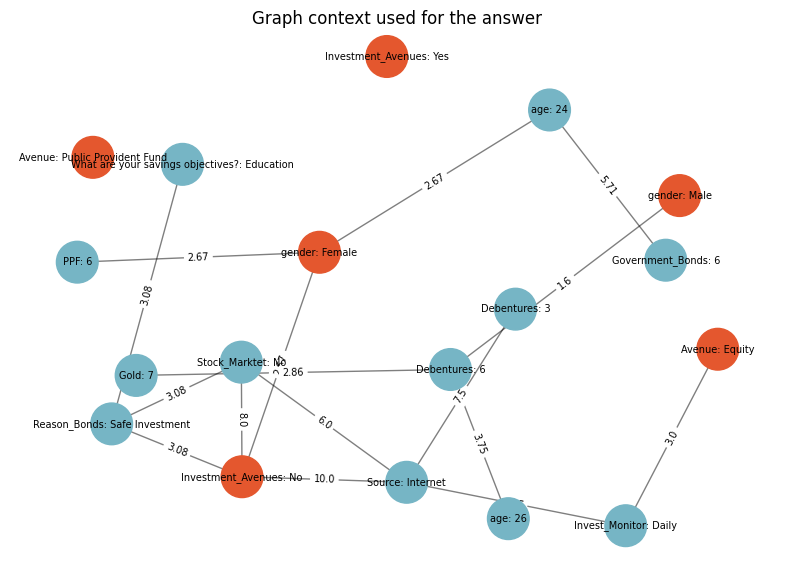

In [16]:
import matplotlib.pyplot as plt

def draw_context(r, figsize=(10, 7)):
    H = nx.Graph()
    seed_labels = {G.nodes[s]["label"] for s in r["seeds"]}
    H.add_nodes_from(seed_labels)
    for t in r["triples"]:
        H.add_edge(t["s"], t["o"], lift=t["lift"], hop=t["hop"])
    if H.number_of_nodes() == 0:
        print("Nothing to draw."); return
    pos = nx.spring_layout(H, seed=7, k=1.2)
    plt.figure(figsize=figsize)
    nx.draw_networkx_nodes(H, pos, node_color=["#e4572e" if n in seed_labels else "#76b5c5" for n in H], node_size=900)
    nx.draw_networkx_edges(H, pos, alpha=0.5)
    nx.draw_networkx_labels(H, pos, font_size=7)
    nx.draw_networkx_edge_labels(H, pos, edge_labels={(u, v): d["lift"] for u, v, d in H.edges(data=True)}, font_size=7)
    plt.axis("off"); plt.title("Graph context used for the answer"); plt.show()

draw_context(ctx)

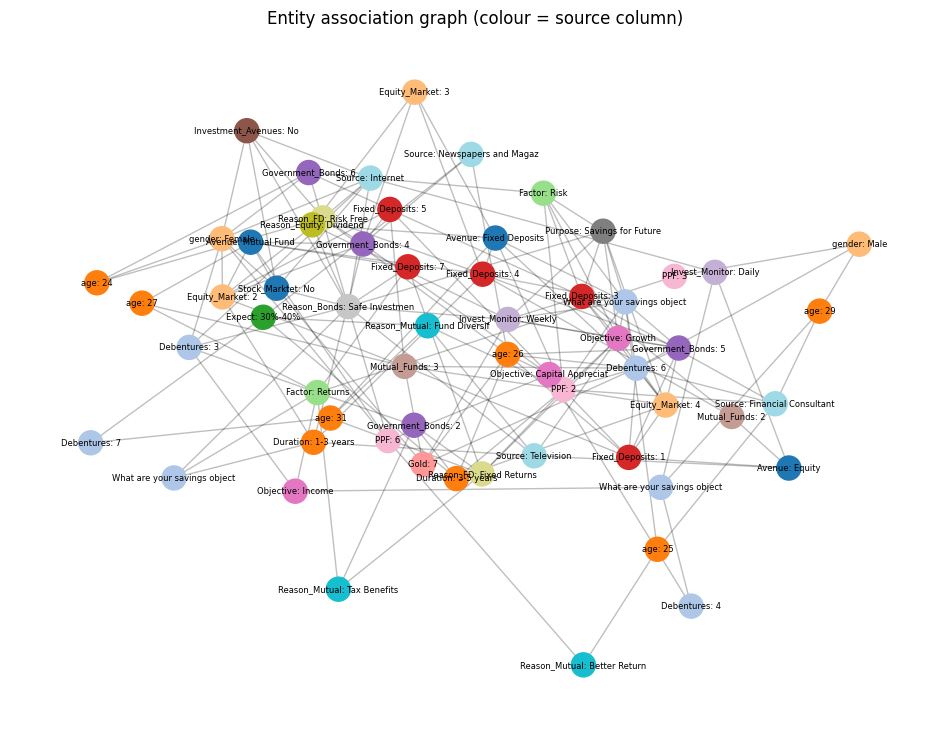

In [17]:
def draw_entity_graph(max_nodes=60, figsize=(12, 9)):
    top = sorted(A.degree, key=lambda x: -x[1])[:max_nodes]
    H = A.subgraph([n for n, _ in top])
    cols = sorted({G.nodes[n]["col"] for n in H})
    cmap = plt.get_cmap("tab20")
    pos = nx.spring_layout(H, seed=3, k=0.6)
    plt.figure(figsize=figsize)
    nx.draw_networkx_nodes(H, pos, node_color=[cmap(cols.index(G.nodes[n]["col"]) % 20) for n in H], node_size=300)
    nx.draw_networkx_edges(H, pos, alpha=0.25)
    nx.draw_networkx_labels(H, pos, labels={n: G.nodes[n]["label"][:28] for n in H}, font_size=6)
    plt.axis("off"); plt.title("Entity association graph (colour = source column)"); plt.show()

draw_entity_graph()

## 12. Interactive chat (optional)
Disabled by default so *Save & Run All* on Kaggle never blocks on `input()`. Set `RUN_CHAT = True` in the config cell to use it interactively.

In [18]:
if RUN_CHAT:
    while True:
        q = input("You (blank/exit to stop): ").strip()
        if q.lower() in {"", "exit", "quit"}:
            break
        a, r = ask(q)
        print("\nBot:", a)
        print("\n[keywords]", r["keywords"], "| [entities]", [G.nodes[s]["label"] for s in r["seeds"]], "\n")
else:
    print("Chat disabled (RUN_CHAT = False).")

Chat disabled (RUN_CHAT = False).
